# ETF 지도 — 이름이 아니라 움직임으로 본 한국 ETF

**AI 프로그래밍 및 실습 프로젝트**

한국에 상장된 ETF는 이름만 보면 수백 가지다. 그런데 실제로 다르게 움직일까?
이 노트북은 ETF 250여 개의 **주간 수익률**만 가지고 세 가지를 한다.

1. **군집화 (6강)**: 비슷하게 움직이는 ETF끼리 묶어 지도를 그린다. 주성분 분석(PCA)과 k-평균을 쓴다.
2. **분류 (3·4·5·7강)**: 움직임만 보고 ETF의 테마(반도체, 중국, 배당 등)를 맞힌다.
   모델이 틀린 ETF는 "이름과 다르게 움직이는 ETF"다.
3. **시장 국면 (6강)**: 이번에는 ETF가 아니라 **주(week)** 를 군집화해 상승·보합·하락 국면을 나누고,
   국면별로 어떤 ETF 군집이 버텼는지 본다.

In [1]:
import json
import os
import re
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. 데이터

- 종목 목록: `data/etf_kr_list.tsv` (한국 상장 ETF 256개, 종목코드와 이름)
- 시세: 야후 파이낸스 일별 종가 (`종목코드.KS`). 받은 값은 `data/etf_kr_close.csv`에 저장한다.

In [2]:
LIST_PATH, CLOSE_PATH = "data/etf_kr_list.tsv", "data/etf_kr_close.csv"
REFRESH = False  # True로 두면 야후 파이낸스에서 다시 받는다

etf = pd.read_csv(LIST_PATH, sep="\t", header=None, names=["code", "name"], dtype=str).set_index("code")

if REFRESH or not os.path.exists(CLOSE_PATH):
    import yfinance as yf

    raw = yf.download([c + ".KS" for c in etf.index], start="2023-01-01", progress=False, auto_adjust=True)["Close"]
    raw.columns = [c[:-3] for c in raw.columns]
    raw.dropna(axis=1, how="all").round(2).to_csv(CLOSE_PATH)

close = pd.read_csv(CLOSE_PATH, index_col=0, parse_dates=True)
close.columns = close.columns.astype(str)
print("일별 종가:", close.shape, "|", close.index.min().date(), "~", close.index.max().date())

일별 종가: (932, 256) | 2023-01-02 ~ 2026-11-25


### 주간 수익률

일별 수익률은 거래가 뜸한 ETF에서 잡음이 크다. 그래서 금요일 종가 기준 **주간 로그수익률**을 쓴다.
비교가 공정하도록 최근 2년(104주) 동안 빠진 주가 없는 ETF만 남긴다.

In [3]:
N_WEEKS = 104
weekly_close = close.resample("W-FRI").last()
weekly_close = weekly_close[weekly_close.index <= close.index.max()]  # 아직 끝나지 않은 주 제외
ret = np.log(weekly_close).diff().iloc[-N_WEEKS:]
ret = ret.dropna(axis=1)
ret = ret.loc[:, (ret == 0).mean() < 0.2]  # 가격이 거의 안 변하는(거래 없는) 종목 제외
etf = etf.loc[ret.columns]
print("분석 대상: ETF %d개 × %d주 (%s ~ %s)" % (ret.shape[1], ret.shape[0], ret.index[0].date(), ret.index[-1].date()))

# ETF별 요약 통계
stats = pd.DataFrame({
    "ret1y": (np.exp(ret.iloc[-52:].sum()) - 1) * 100,   # 최근 1년 수익률(%)
    "vol": ret.std() * np.sqrt(52) * 100,                # 연율화 변동성(%)
})
etf = etf.join(stats)
etf.sort_values("ret1y", ascending=False).head(5).round(1)

분석 대상: ETF 251개 × 104주 (2024-11-29 ~ 2026-11-20)


,name,ret1y,vol
395270,HANARO Fn K-반도체,108.0,54.3
367760,RISE 5G테크,93.7,53.4
130680,TIGER 원유선물Enhanced(H),89.8,43.6
139260,TIGER 200 IT,84.6,52.3
261220,KODEX WTI원유선물(H),83.8,45.4


## 2. 이름으로 테마 붙이기

ETF 이름에 들어 있는 단어로 테마를 붙인다. 위에서부터 차례로 검사해 처음 맞는 규칙을 쓴다.
이 테마는 **"이름이 말하는 분류"** 이고, 뒤에서 **"움직임이 말하는 분류"** 와 비교한다.

In [4]:
THEME_RULES = [
    ("커버드콜", "커버드콜"),
    ("원자재", "금현물|골드|금은|은선물|구리|원유|농산물|금채굴"),
    ("중국", "차이나|중국"),
    ("일본·유럽", "일본|유로|독일|유럽"),
    ("인도·신흥국", "인도|베트남|신흥국"),
    ("반도체", "반도체|TSMC|하이닉스"),
    ("2차전지·모빌리티", "2차전지|리튬|전기차|양극재|테슬라|자율주행|모빌리티|자동차"),
    ("바이오·헬스케어", "바이오|헬스케어|의료|비만"),
    ("방산·조선·원자력", "방산|조선|원자력|우주|중공업|기계|전력"),
    ("미디어·게임", "게임|미디어|콘텐츠|K-POP|KPOP|웹툰|메타버스"),
    ("소비재", "화장품|뷰티|푸드|여행|필수소비재|경기방어|컨슈머"),
    ("금융", "은행|증권|보험|금융|지주"),
    ("배당·가치", "배당|캐시카우|WideMoat|버크셔"),
    ("AI·빅테크", "AI|빅테크|테크|클라우드|소프트웨어|사이버보안|4차산업|서학개미|베스트셀러|성장기업|로봇|인터넷|5G| IT|IT$|엔비디아|마이크로소프트|구글"),
    ("친환경·소재", "수소|태양광|신재생|클린에너지|에너지화학|철강|희토류|건설|운송|인프라|유틸리티"),
    ("미국 대표지수", "S&P500|나스닥100|미국500|러셀|선진국|글로벌주식|빌리어네어"),
    ("한국 대표지수", "200|코스피|코스닥150|KRX300|밸류업|코리아|이노베이션|BBIG|KEDI"),
]


def name_to_theme(name):
    for theme, pattern in THEME_RULES:
        if re.search(pattern, name):
            return theme
    return "기타"


etf["theme"] = etf["name"].map(name_to_theme)
THEMES = [t for t, _ in THEME_RULES if t in set(etf["theme"])]
print(etf["theme"].value_counts().to_string())

theme
AI·빅테크       36
반도체          23
방산·조선·원자력    21
미국 대표지수      19
커버드콜         19
중국           17
친환경·소재       14
바이오·헬스케어     14
2차전지·모빌리티    13
배당·가치        13
한국 대표지수      12
원자재          11
미디어·게임       10
일본·유럽         9
금융            7
인도·신흥국        7
소비재           6


## 3. 상관관계: 쌍둥이 ETF

두 ETF의 주간 수익률 상관계수가 1에 가까우면 사실상 같은 상품이다.
운용사만 다른 같은 지수 ETF는 당연히 쌍둥이다. 더 흥미로운 것은 **테마 이름이 다른데도 쌍둥이인 경우**다.

In [5]:
corr = ret.corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("corr").reset_index()
pairs.columns = ["a", "b", "corr"]
pairs["name_a"], pairs["name_b"] = pairs["a"].map(etf["name"]), pairs["b"].map(etf["name"])
pairs["theme_a"], pairs["theme_b"] = pairs["a"].map(etf["theme"]), pairs["b"].map(etf["theme"])

print("상관계수 0.95 이상인 쌍: %d개 / 전체 %d쌍" % ((pairs["corr"] >= 0.95).sum(), len(pairs)))
diff = pairs[pairs["theme_a"] != pairs["theme_b"]].sort_values("corr", ascending=False)
is_cc = (diff["theme_a"] == "커버드콜") | (diff["theme_b"] == "커버드콜")
print("\n커버드콜 ETF와 그 기초자산 ETF")
diff[is_cc][["name_a", "name_b", "corr"]].head(5).round(3)

상관계수 0.95 이상인 쌍: 216개 / 전체 63001쌍

커버드콜 ETF와 그 기초자산 ETF


,name_a,name_b,corr
33594,WON 미국S&P500,TIGER 미국S&P500타겟데일리커버드콜,0.996
17028,TIGER 미국S&P500,TIGER 미국S&P500타겟데일리커버드콜,0.996
30833,SOL 미국S&P500,TIGER 미국S&P500타겟데일리커버드콜,0.996
18546,ACE 미국나스닥100,TIGER 미국나스닥100타겟데일리커버드콜,0.995
39565,TIGER 미국배당다우존스,TIGER 미국배당다우존스타겟커버드콜1호,0.993


커버드콜 ETF는 주간 수익률 기준으로 기초자산 ETF와 상관계수가 0.99를 넘는다.
분배금 구조는 다르지만 **가격이 움직이는 방향은 기초자산과 같다**는 뜻이다.

커버드콜을 빼고, 테마 이름이 다른데 가장 비슷하게 움직이는 쌍을 본다(ETF 하나는 한 번만 나오게 했다).

In [6]:
seen, rows = set(), []
for _, r in diff[~is_cc].iterrows():
    if r["a"] in seen or r["b"] in seen:
        continue
    seen.update([r["a"], r["b"]])
    rows.append(r)
    if len(rows) == 12:
        break
twins_diff = pd.DataFrame(rows)
twins_diff[["name_a", "theme_a", "name_b", "theme_b", "corr"]].round(3)

,name_a,theme_a,name_b,theme_b,corr
20550,TIGER 미국테크TOP10 INDXX,AI·빅테크,KCGI 미국S&P500 TOP10,미국 대표지수,0.986
13144,KODEX IT,AI·빅테크,HANARO Fn K-반도체,반도체,0.982
46627,TIGER 코리아테크액티브,AI·빅테크,WON 반도체밸류체인액티브,반도체,0.967
3908,TIGER 200 IT,AI·빅테크,1Q K200액티브,한국 대표지수,0.964
15511,KODEX KRX300,한국 대표지수,KoAct 배당성장액티브,배당·가치,0.960
22053,KODEX 미국반도체,반도체,ACE 엔비디아밸류체인액티브,AI·빅테크,0.953
43903,ACE 미국빅테크TOP7 Plus,AI·빅테크,WON 미국빌리어네어,미국 대표지수,0.946
32879,TIMEFOLIO Korea플러스배당액티브,배당·가치,TIGER 코리아밸류업,한국 대표지수,0.942
18665,RISE 5G테크,AI·빅테크,KODEX AI반도체,반도체,0.940
18543,ACE 미국나스닥100,미국 대표지수,KODEX 미국AI테크TOP10,AI·빅테크,0.929


## 4. 주성분 분석 (6강)

ETF 하나가 표본 하나이고, 104주의 수익률이 특성 104개다.
먼저 ETF마다 수익률을 표준화한다(평균 0, 표준편차 1). 이렇게 하면 변동 폭이 아니라 **움직이는 모양**만 비교하게 된다.

특성이 104개나 되므로 PCA로 차원을 줄인다.

주성분 1개: 19.3% | 2개: 36.0% | 10개: 69.3%


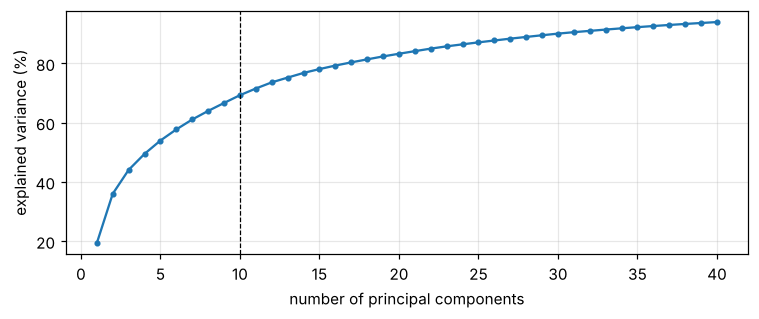

In [7]:
X = ((ret - ret.mean()) / ret.std()).T.values   # (ETF 수, 104)
pca_full = PCA(random_state=SEED).fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)

N_PC = 10
print("주성분 1개: %.1f%% | 2개: %.1f%% | %d개: %.1f%%" % (cum[0] * 100, cum[1] * 100, N_PC, cum[N_PC - 1] * 100))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, 41), cum[:40] * 100, marker="o", ms=3)
ax.axvline(N_PC, color="k", ls="--", lw=0.8)
ax.set_xlabel("number of principal components")
ax.set_ylabel("explained variance (%)")
plt.tight_layout()
plt.show()

PC1 양 끝: 한국 대표지수 <-> 배당·가치
PC2 양 끝: 반도체 <-> 소비재


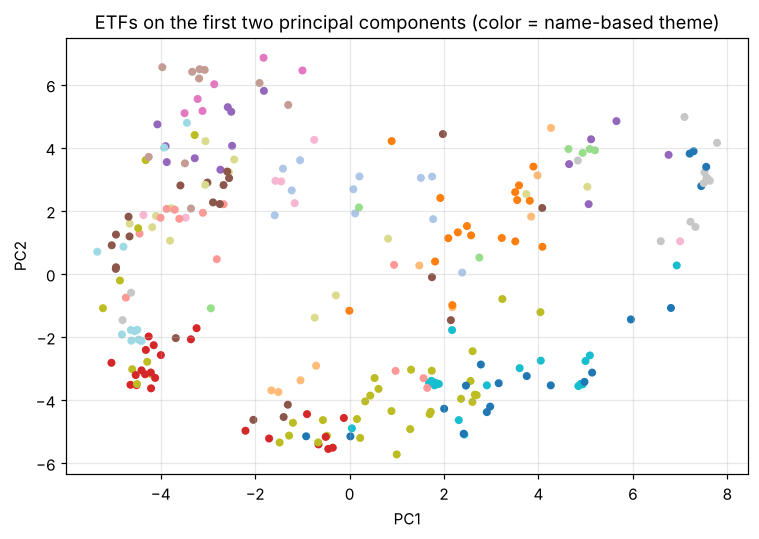

In [8]:
pca = PCA(n_components=N_PC, random_state=SEED)
Z = pca.fit_transform(X)

# 주성분의 의미: 테마별 평균 점수를 보면 각 축이 어떤 ETF들을 갈라놓는지 알 수 있다
pc_by_theme = pd.DataFrame(Z[:, :2], index=etf.index, columns=["PC1", "PC2"]).groupby(etf["theme"]).mean()
print("PC1 양 끝:", pc_by_theme["PC1"].idxmin(), "<->", pc_by_theme["PC1"].idxmax())
print("PC2 양 끝:", pc_by_theme["PC2"].idxmin(), "<->", pc_by_theme["PC2"].idxmax())

theme_id = etf["theme"].map({t: i for i, t in enumerate(THEMES)})
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(Z[:, 0], Z[:, 1], c=theme_id, cmap="tab20", s=18)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("ETFs on the first two principal components (color = name-based theme)")
plt.tight_layout()
plt.show()

## 5. k-평균 군집화 (6강)

주성분 10개 공간에서 k-평균으로 묶는다. 군집 수 k는 이너셔(엘보우)와 실루엣 계수를 보고 정한다.

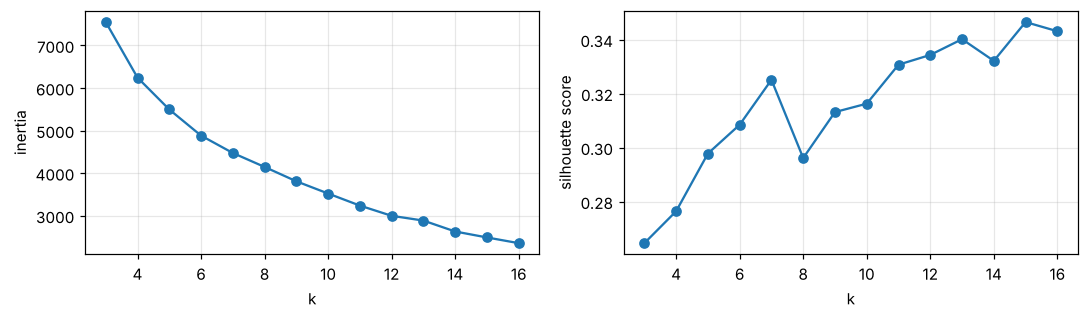

In [9]:
ks = range(3, 17)
inertia, sil = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    inertia.append(km_k.inertia_)
    sil.append(silhouette_score(Z, km_k.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(ks, inertia, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[1].plot(ks, sil, marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette score")
plt.tight_layout()
plt.show()

이너셔는 뚜렷하게 꺾이는 지점 없이 완만하게 줄고, 실루엣 계수도 k에 따라 크게 달라지지 않는다.
금융 자산은 군집 경계가 칼같이 나뉘지 않기 때문이다. 여기서는 군집 하나하나를 사람이 해석할 수 있는 크기인 **k = 10**을 쓴다.

In [10]:
K = 10
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
# 군집 번호를 크기순으로 다시 매긴다
order = pd.Series(km.labels_).value_counts().index
relabel = {old: new for new, old in enumerate(order)}
etf["cluster"] = [relabel[c] for c in km.labels_]


def cluster_name(members):
    top = members["theme"].value_counts()
    names = [top.index[0]]
    if len(top) > 1 and top.iloc[1] >= 0.2 * len(members):
        names.append(top.index[1])
    return " + ".join(names)


cluster_info = []
for c in range(K):
    m = etf[etf["cluster"] == c]
    cluster_info.append({
        "cluster": c, "name": cluster_name(m), "n": len(m),
        "ret1y": m["ret1y"].mean(), "vol": m["vol"].mean(),
        "themes": m["theme"].value_counts().head(4).to_dict(),
        "examples": ", ".join(m["name"].head(4)),
    })
cluster_df = pd.DataFrame(cluster_info).set_index("cluster")
# 이름이 겹치는 군집은 대표 ETF를 붙여 구분한다
for c in cluster_df.index[cluster_df["name"].duplicated(keep=False)]:
    cluster_df.loc[c, "name"] += " (" + etf.loc[etf["cluster"] == c, "name"].iloc[0] + " 등)"
pd.set_option("display.max_colwidth", 90)
cluster_df[["name", "n", "ret1y", "vol", "examples"]].round(1)

,name,n,ret1y,vol,examples
cluster,,,,,
0,미국 대표지수 + AI·빅테크,47,-2.9,20.7,"KODEX 일본TOPIX100, TIGER 미국S&P500선물(H), KODEX 미국S&P500선물(H), KODEX MSCI선진국"
1,반도체 + 한국 대표지수,34,39.9,45.9,"TIGER 반도체, ACE 200, TIGER 200 IT, PLUS 신흥국MSCI(합성 H)"
2,AI·빅테크 + 반도체,34,6.0,34.7,"ACE 일본Nikkei225(H), TIGER 일본니케이225, TIGER 글로벌4차산업혁신기술(합성 H), TIGER 미국필라델피아반도체나스닥"
3,방산·조선·원자력 + 친환경·소재,31,-19.9,44.9,"KODEX 자동차, KODEX 기계장비, KODEX 에너지화학, KODEX 철강"
4,배당·가치,31,6.3,16.5,"KIWOOM 인도Nifty50(합성), TIGER 미국나스닥바이오, KODEX S&P글로벌인프라(합성), ACE 미국WideMoat동일가중"
5,바이오·헬스케어 + 미디어·게임,20,-25.9,31.0,"TIGER 헬스케어, TIGER 소프트웨어, KODEX 바이오, TIGER 코스닥150바이오테크"
6,원자재 + 일본·유럽,19,-15.5,26.8,"KODEX 골드선물(H), KODEX 구리선물(H), TIGER 금은선물(H), KODEX 은선물(H)"
7,소비재 + 금융,16,-2.5,30.1,"TIGER 은행, TIGER 200 금융, TIGER 경기방어, KODEX 보험"
8,중국,15,-18.3,28.8,"RISE 중국본토대형주CSI100, TIGER 차이나CSI300, KODEX 차이나심천ChiNext(합성), KODEX 차이나CSI300"


In [11]:
for c in range(K):
    print(f"[{c}] {cluster_df.loc[c, 'name']} ({cluster_df.loc[c, 'n']}개):", cluster_df.loc[c, "themes"])

[0] 미국 대표지수 + AI·빅테크 (47개): {'미국 대표지수': 18, 'AI·빅테크': 15, '커버드콜': 11, '2차전지·모빌리티': 2}
[1] 반도체 + 한국 대표지수 (34개): {'반도체': 15, '한국 대표지수': 8, 'AI·빅테크': 6, '2차전지·모빌리티': 2}
[2] AI·빅테크 + 반도체 (34개): {'AI·빅테크': 12, '반도체': 8, '방산·조선·원자력': 5, '일본·유럽': 4}
[3] 방산·조선·원자력 + 친환경·소재 (31개): {'방산·조선·원자력': 13, '친환경·소재': 8, '2차전지·모빌리티': 7, '한국 대표지수': 2}
[4] 배당·가치 (31개): {'배당·가치': 11, '커버드콜': 6, '바이오·헬스케어': 5, '인도·신흥국': 4}
[5] 바이오·헬스케어 + 미디어·게임 (20개): {'바이오·헬스케어': 9, '미디어·게임': 6, 'AI·빅테크': 3, '한국 대표지수': 2}
[6] 원자재 + 일본·유럽 (19개): {'원자재': 7, '일본·유럽': 4, '인도·신흥국': 2, '중국': 2}
[7] 소비재 + 금융 (16개): {'소비재': 6, '금융': 5, '미디어·게임': 4, '친환경·소재': 1}
[8] 중국 (15개): {'중국': 15}
[9] 원자재 (4개): {'원자재': 4}


### 지도 그리기

PCA 2개 축만으로는 군집이 겹쳐 보인다. 화면에 그릴 때는 가까운 점끼리의 관계를 잘 보존하는 t-SNE로 2차원 좌표를 만든다.
t-SNE는 **그림을 그리는 용도로만** 쓰고, 군집은 위에서 k-평균으로 정한 것을 그대로 색칠한다.

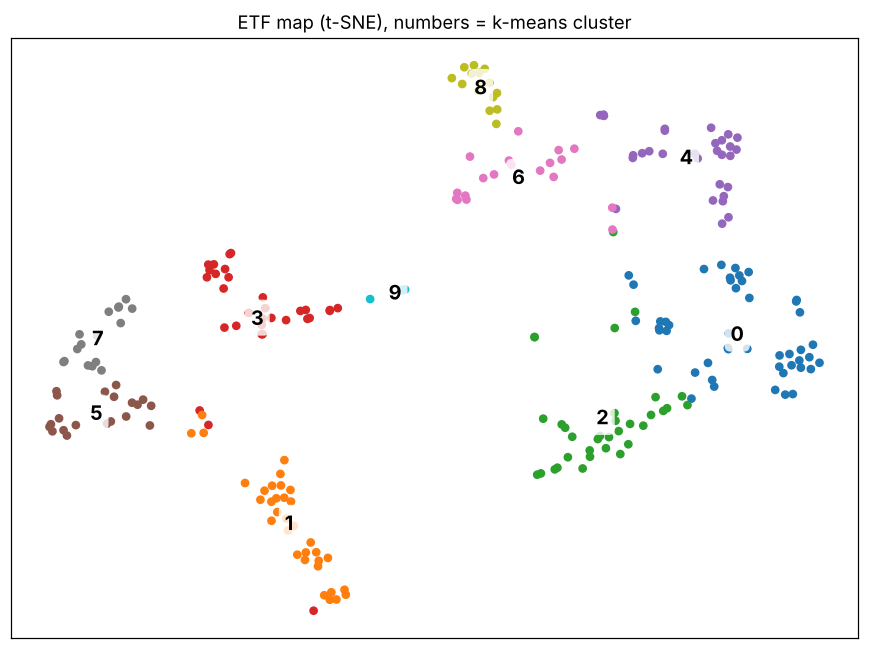

In [12]:
xy = TSNE(n_components=2, perplexity=20, init="pca", random_state=SEED).fit_transform(Z)
etf["x"], etf["y"] = xy[:, 0], xy[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(etf["x"], etf["y"], c=etf["cluster"], cmap="tab10", s=22)
for c in range(K):
    m = etf[etf["cluster"] == c]
    ax.text(m["x"].mean(), m["y"].mean(), str(c), fontsize=13, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round", fc="white", alpha=0.8, lw=0))
ax.set_title("ETF map (t-SNE), numbers = k-means cluster")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

## 6. 움직임만 보고 테마 맞히기 (지도 학습)

이번에는 이름으로 붙인 테마를 **정답**으로 두고, 수익률 움직임(주성분)만으로 테마를 맞히는 분류 모델을 만든다.

- 표본이 250개 정도로 적어서 훈련/테스트로 한 번 나누는 대신 **5-폴드 교차 검증**을 쓴다(5강).
- 표준화와 PCA는 파이프라인 안에 넣어 폴드마다 훈련 데이터로만 맞춘다.
- 테마가 18개이므로 아무거나 찍으면 정확도는 6% 안팎, 가장 많은 테마로만 찍어도 15% 안팎이다.

In [13]:
mask = (etf["theme"] != "기타").values
Xc, yc = X[mask], etf.loc[mask, "theme"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def pipe(model, n_pc=20):
    return make_pipeline(PCA(n_components=n_pc, random_state=SEED), StandardScaler(), model)


MODELS = {
    "k-최근접 이웃": (pipe(KNeighborsClassifier(n_neighbors=5)), "3강"),
    "로지스틱 회귀": (pipe(LogisticRegression(C=1.0, max_iter=3000)), "4강"),
    "결정 트리": (pipe(DecisionTreeClassifier(max_depth=6, random_state=SEED)), "5강"),
    "랜덤 포레스트": (pipe(RandomForestClassifier(n_estimators=300, random_state=SEED)), "5강"),
    "신경망 (MLP)": (pipe(MLPClassifier(hidden_layer_sizes=(64,), alpha=0.01, max_iter=3000, random_state=SEED)), "7강"),
}

majority = pd.Series(yc).value_counts(normalize=True).iloc[0]
cls_rows = [{"model": "기준선 (가장 많은 테마로 찍기)", "lecture": "-", "accuracy": majority, "macro_f1": np.nan}]
cv_proba = {}
for name, (model, lecture) in MODELS.items():
    proba = cross_val_predict(model, Xc, yc, cv=cv, method="predict_proba")
    classes = np.unique(yc)
    pred = classes[proba.argmax(axis=1)]
    cv_proba[name] = (proba, pred)
    cls_rows.append({"model": name, "lecture": lecture, "accuracy": accuracy_score(yc, pred),
                     "macro_f1": f1_score(yc, pred, average="macro")})
cls_df = pd.DataFrame(cls_rows).set_index("model")
cls_df.round(3)

,lecture,accuracy,macro_f1
model,,,
기준선 (가장 많은 테마로 찍기),-,0.143,NaN
k-최근접 이웃,3강,0.665,0.680
로지스틱 회귀,4강,0.765,0.766
결정 트리,5강,0.430,0.393
랜덤 포레스트,5강,0.753,0.769
신경망 (MLP),7강,0.757,0.762


In [14]:
BEST = cls_df["accuracy"].iloc[1:].idxmax()
proba, pred = cv_proba[BEST]
classes = np.unique(yc)
print("가장 정확한 모델:", BEST)

by_theme = pd.DataFrame({"theme": yc, "hit": pred == yc}).groupby("theme")["hit"].agg(["mean", "size"])
by_theme.columns = ["정확도", "ETF 수"]
by_theme.sort_values("정확도", ascending=False).round(2)

가장 정확한 모델: 로지스틱 회귀


,정확도,ETF 수
theme,,
중국,1.00,17
원자재,1.00,11
방산·조선·원자력,0.95,21
바이오·헬스케어,0.93,14
반도체,0.91,23
미디어·게임,0.90,10
일본·유럽,0.89,9
2차전지·모빌리티,0.85,13
소비재,0.83,6


테마마다 정확도가 크게 다르다. 중국·원자재처럼 **다른 것과 따로 움직이는 테마**는 잘 맞히고,
서로 비슷하게 움직이는 테마들은 헷갈린다.

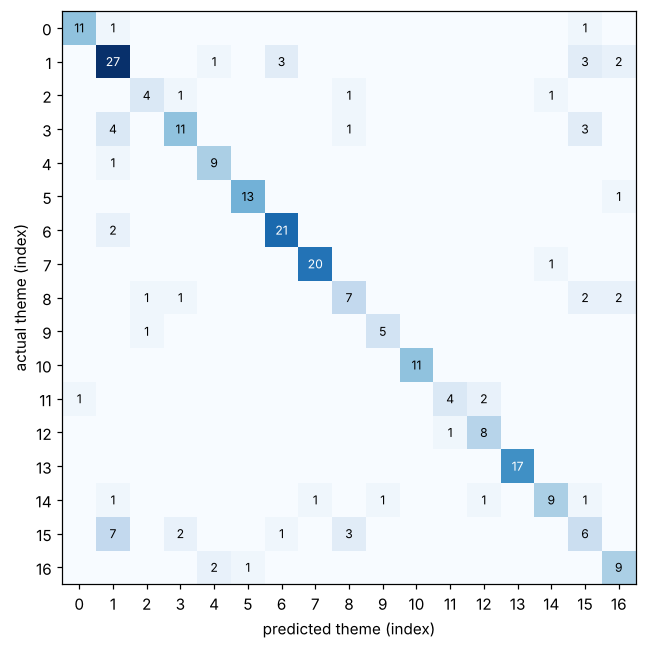

{0: '2차전지·모빌리티', 1: 'AI·빅테크', 2: '금융', 3: '미국 대표지수', 4: '미디어·게임', 5: '바이오·헬스케어', 6: '반도체', 7: '방산·조선·원자력', 8: '배당·가치', 9: '소비재', 10: '원자재', 11: '인도·신흥국', 12: '일본·유럽', 13: '중국', 14: '친환경·소재', 15: '커버드콜', 16: '한국 대표지수'}


In [15]:
conf = pd.crosstab(pd.Series(yc, name="actual"), pd.Series(pred, name="predicted")).reindex(index=classes, columns=classes, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(conf.values, cmap="Blues")
ax.set_xticks(range(len(classes)), range(len(classes)))
ax.set_yticks(range(len(classes)), range(len(classes)))
for i in range(len(classes)):
    for j in range(len(classes)):
        if conf.values[i, j]:
            ax.text(j, i, conf.values[i, j], ha="center", va="center", fontsize=8,
                    color="white" if conf.values[i, j] > conf.values.max() / 2 else "black")
ax.set_xlabel("predicted theme (index)")
ax.set_ylabel("actual theme (index)")
ax.grid(False)
plt.tight_layout()
plt.show()
print({i: c for i, c in enumerate(classes)})

### 이름과 다르게 움직이는 ETF

모델이 **확신을 갖고 틀린** ETF를 뽑는다. 이름은 A 테마인데 움직임은 B 테마에 가깝다는 뜻이다.

In [16]:
etf["pred"], etf["pred_p"] = etf["theme"], np.nan
etf.loc[mask, "pred"] = pred
etf.loc[mask, "pred_p"] = proba.max(axis=1)
odd = etf[mask & (etf["pred"] != etf["theme"])].sort_values("pred_p", ascending=False)
print("틀린 ETF: %d개 / %d개" % (len(odd), mask.sum()))
odd[["name", "theme", "pred", "pred_p"]].head(15).round(2)

틀린 ETF: 59개 / 251개


,name,theme,pred,pred_p
490590,RISE 미국AI밸류체인데일리고정커버드콜,커버드콜,AI·빅테크,0.83
491830,TIGER 미국AI반도체팹리스,반도체,AI·빅테크,0.80
441640,KODEX 미국배당커버드콜액티브,커버드콜,미국 대표지수,0.79
471780,TIGER 코리아테크액티브,AI·빅테크,반도체,0.77
480040,ACE 미국반도체데일리타겟커버드콜(합성),커버드콜,반도체,0.73
458750,TIGER 미국배당다우존스타겟커버드콜1호,커버드콜,배당·가치,0.72
456250,KODEX 유럽명품TOP10 STOXX,일본·유럽,인도·신흥국,0.71
444200,SOL 코리아메가테크액티브,AI·빅테크,한국 대표지수,0.70
458760,TIGER 미국배당다우존스타겟커버드콜2호,커버드콜,배당·가치,0.68
453650,KODEX 미국S&P500금융,금융,미국 대표지수,0.68


## 7. 시장 국면: 주(week)를 군집화하기

지금까지는 ETF를 묶었다. 이번에는 같은 k-평균으로 **104개의 주**를 묶는다.
주마다 두 가지 특성을 만든다.

- 시장 수익률: 그 주 전체 ETF 수익률의 평균
- 흩어짐: 그 주 ETF 수익률의 표준편차 (ETF들이 제각각 움직였는지)

세 군집으로 나누고, 평균 수익률이 높은 순서로 **상승 / 보합 / 하락**이라고 이름 붙인다.

In [17]:
weeks = pd.DataFrame({"market": ret.mean(axis=1) * 100, "dispersion": ret.std(axis=1) * 100})
km_w = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(StandardScaler().fit_transform(weeks))
rank = weeks.groupby(km_w.labels_)["market"].mean().sort_values(ascending=False).index
REGIMES = ["상승", "보합", "하락"]
weeks["regime"] = pd.Series(km_w.labels_, index=weeks.index).map({old: REGIMES[i] for i, old in enumerate(rank)})
regime_df = weeks.groupby("regime").agg(weeks=("market", "size"), market=("market", "mean"), dispersion=("dispersion", "mean")).loc[REGIMES]
regime_df.round(2)

,weeks,market,dispersion
regime,,,
상승,15,2.44,5.23
보합,73,0.71,3.11
하락,16,-3.92,5.15


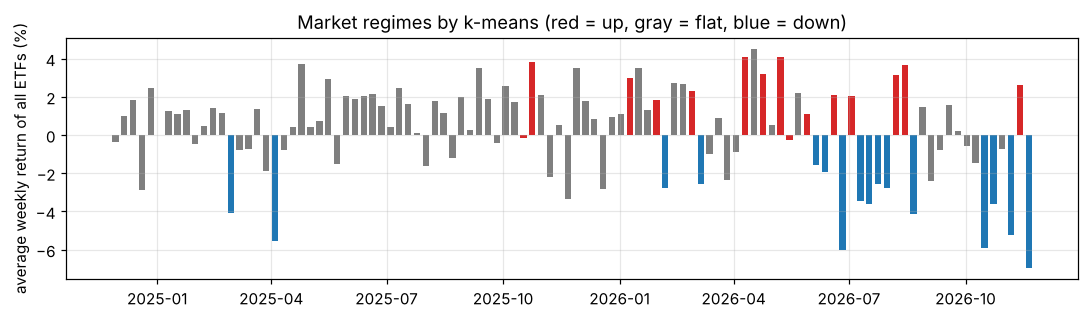

In [18]:
fig, ax = plt.subplots(figsize=(10, 3))
colors = {"상승": "tab:red", "보합": "tab:gray", "하락": "tab:blue"}
ax.bar(weeks.index, weeks["market"], width=5, color=weeks["regime"].map(colors))
ax.set_ylabel("average weekly return of all ETFs (%)")
ax.set_title("Market regimes by k-means (red = up, gray = flat, blue = down)")
plt.tight_layout()
plt.show()

### 국면별로 어떤 ETF 군집이 버텼나

ETF 군집(행)과 시장 국면(열)을 교차해 주간 평균 수익률(%)을 본다.
하락 국면에서 덜 떨어지거나 오히려 오른 군집이 **분산 투자에 실제로 도움이 되는 군집**이다.

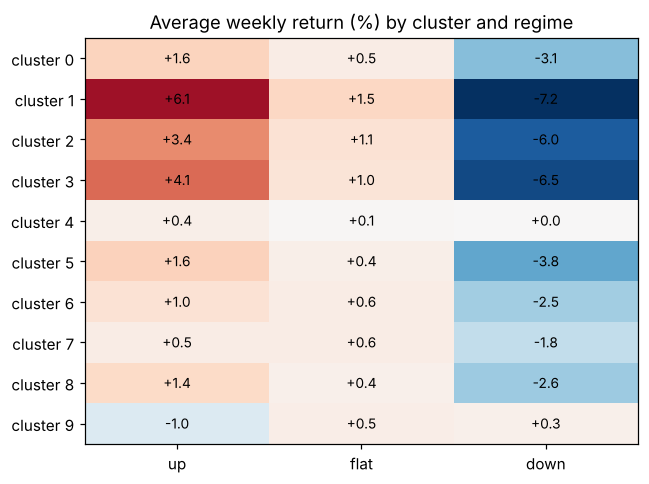

,상승,보합,하락
[0] 미국 대표지수 + AI·빅테크,1.58,0.54,-3.08
[1] 반도체 + 한국 대표지수,6.10,1.47,-7.19
[2] AI·빅테크 + 반도체,3.39,1.06,-5.98
[3] 방산·조선·원자력 + 친환경·소재,4.08,0.95,-6.50
[4] 배당·가치,0.40,0.09,0.01
[5] 바이오·헬스케어 + 미디어·게임,1.63,0.39,-3.75
[6] 원자재 + 일본·유럽,1.01,0.56,-2.51
[7] 소비재 + 금융,0.51,0.55,-1.79
[8] 중국,1.38,0.39,-2.64
[9] 원자재,-0.99,0.50,0.34


In [19]:
regime_ret = pd.DataFrame({
    r: [ret.loc[weeks["regime"] == r, etf.index[etf["cluster"] == c]].mean().mean() * 100 for c in range(K)]
    for r in REGIMES
})
regime_ret.index = [f"[{c}] {cluster_df.loc[c, 'name']}" for c in range(K)]

fig, ax = plt.subplots(figsize=(6, 4.5))
lim = np.abs(regime_ret.values).max()
ax.imshow(regime_ret.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(3), ["up", "flat", "down"])
ax.set_yticks(range(K), [f"cluster {c}" for c in range(K)])
for i in range(K):
    for j in range(3):
        ax.text(j, i, f"{regime_ret.values[i, j]:+.1f}", ha="center", va="center", fontsize=9)
ax.grid(False)
ax.set_title("Average weekly return (%) by cluster and regime")
plt.tight_layout()
plt.show()
regime_ret.round(2)

## 8. 웹 페이지용 결과 내보내기

웹 페이지(`docs/index.html`)가 읽는 `docs/etf_data.js`를 만든다.
ETF마다 가장 비슷하게 움직이는 5개와 가장 다르게 움직이는 5개도 함께 넣는다.

In [20]:
codes = list(etf.index)
pos = {c: i for i, c in enumerate(codes)}
C = corr.loc[codes, codes].values
kospi_code = etf.index[etf["name"] == "TIGER 코스피"][0] if (etf["name"] == "TIGER 코스피").any() else codes[0]


def rnd(v, n=2):
    return None if pd.isna(v) else round(float(v), n)


items = []
for i, code in enumerate(codes):
    row = etf.loc[code]
    order_i = np.argsort(-C[i])
    near = [j for j in order_i if j != i][:5]
    far = list(order_i[::-1][:5])
    items.append({
        "code": code, "name": row["name"], "theme": row["theme"], "cluster": int(row["cluster"]),
        "x": rnd(row["x"]), "y": rnd(row["y"]), "ret1y": rnd(row["ret1y"], 1), "vol": rnd(row["vol"], 1),
        "kospi": rnd(C[i, pos[kospi_code]]),
        "pred": row["pred"], "pred_p": rnd(row["pred_p"]),
        "near": [[int(j), rnd(C[i, j])] for j in near],
        "far": [[int(j), rnd(C[i, j])] for j in far],
    })

export = {
    "generated": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "period": [ret.index[0].strftime("%Y-%m-%d"), ret.index[-1].strftime("%Y-%m-%d")],
    "n_weeks": int(ret.shape[0]),
    "themes": THEMES + (["기타"] if (etf["theme"] == "기타").any() else []),
    "etfs": items,
    "clusters": [
        {"id": c, "name": cluster_df.loc[c, "name"], "n": int(cluster_df.loc[c, "n"]),
         "ret1y": rnd(cluster_df.loc[c, "ret1y"], 1), "vol": rnd(cluster_df.loc[c, "vol"], 1),
         "themes": cluster_df.loc[c, "themes"],
         "regime": [rnd(v) for v in regime_ret.iloc[c]]}
        for c in range(K)
    ],
    "regimes": [{"name": r, "weeks": int(regime_df.loc[r, "weeks"]), "market": rnd(regime_df.loc[r, "market"])} for r in REGIMES],
    "models": [{"name": n, "lecture": r["lecture"], "accuracy": rnd(r["accuracy"], 3), "macro_f1": rnd(r["macro_f1"], 3)}
               for n, r in cls_df.iterrows()],
    "best_model": BEST,
    "n_themes": int(len(classes)),
    "odd": [{"i": pos[c], "theme": r["theme"], "pred": r["pred"], "p": rnd(r["pred_p"])} for c, r in odd.head(12).iterrows()],
    "twins": [{"a": pos[r["a"]], "b": pos[r["b"]], "corr": rnd(r["corr"], 3)} for _, r in twins_diff.head(10).iterrows()],
    "pca": {"pc1": rnd(cum[0] * 100, 1), "pc2": rnd(cum[1] * 100, 1), "n_pc": N_PC, "cum": rnd(cum[N_PC - 1] * 100, 1)},
    "kospi_name": etf.loc[kospi_code, "name"],
}
os.makedirs("docs", exist_ok=True)
with open("docs/etf_data.js", "w", encoding="utf-8") as f:
    f.write("window.ETF_DATA = " + json.dumps(export, ensure_ascii=False) + ";\n")
print("docs/etf_data.js 저장:", os.path.getsize("docs/etf_data.js") // 1024, "KB")

docs/etf_data.js 저장: 92 KB


## 정리

- ETF 이름은 수백 가지지만 움직임으로 묶으면 10개 안팎의 무리로 정리된다.
- 주간 수익률만으로 ETF의 테마를 찍는 것보다 훨씬 잘 맞힐 수 있다. 수익률의 움직임에 테마 정보가 들어 있다는 뜻이다.
- 모델이 틀린 ETF, 테마가 다른데 상관이 높은 쌍은 "이름만 보고 분산 투자했다고 착각하기 쉬운" 사례다.
- 같은 k-평균을 주(week)에 적용하면 시장 국면이 나오고, 국면별로 어떤 군집이 버텼는지 볼 수 있다.

**한계**
- 테마 정답은 이름의 단어로 붙인 것이라 완벽하지 않다. 규칙을 바꾸면 정확도도 달라진다.
- 최근 2년 수익률만 썼다. 기간이 달라지면 군집도 달라질 수 있다.
- 과거에 같이 움직였다는 사실이 앞으로도 그렇다는 보장은 아니다. 투자 권유가 아니다.